# Wakely: detecção de sonolência ao volante

**Grupo:** Antônio Dias, Rafael Capozzielli e _(3º integrante)_ · Insper AI, entrega final 2026.2

> O Wakely é um **protótipo acadêmico**. Não é um dispositivo de segurança e **nunca deve ser testado dirigindo**.

Uma webcam olha o rosto do motorista e o sistema avisa quando o olho fica fechado por tempo demais. Este notebook é a primeira versão, para a apresentação intermediária de 12/11. Ele tem a linha de base sem deep learning (MediaPipe + EAR + regras) e a CNN de olho com fine-tuning, testadas em vídeos reais de motoristas à noite. O modelo temporal (GRU ou TCN) fica para a entrega final.

### Sumário

| Seção | Conteúdo |
|---|---|
| 1 | Configuração e dados (MRL Eye e FL3D) |
| 2 | Linha de base: MediaPipe + EAR + regras do Euro NCAP |
| 3 | CNN de olho: MobileNetV3 com fine-tuning, separada por pessoa |
| 4 | CNN no vídeo: a CNN no lugar do EAR, na mesma regra |
| 5 | Resumo e próximos passos |

### Como rodar

1. `uv sync` na raiz do repositório (Python 3.12, PyTorch com CUDA, MediaPipe).
2. Rodar o notebook do início. A seção 1 baixa os dados para `data/`, que fica fora do git porque tem rostos de pessoas.
3. Os resultados pesados (landmarks do vídeo e pesos da CNN) ficam em cache em `data/`. Na segunda execução eles são carregados em vez de recalculados.

### O pipeline

![Pipeline recomendado](docs/pipeline_recomendado.png)

A escolha vem da pesquisa do grupo (`docs/pesquisa_wakely.md`). O MediaPipe acha o rosto e os olhos, a CNN dá P(olho fechado) em cada frame e uma regra transforma a sequência em alerta. Neste notebook a GRU/TCN ainda não entra: a regra temporal é a de tempo de olho fechado do Euro NCAP.

## 1. Configuração e dados

In [1]:
import json
import os
import re
import time
import random
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay)

import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

# reprodutibilidade
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("MediaPipe", mp.__version__)

DADOS = Path("data")
CACHE = DADOS / "cache"
PASTA_MODELOS = DADOS / "modelos"
for p in (DADOS, CACHE, PASTA_MODELOS):
    p.mkdir(parents=True, exist_ok=True)

FPS = 25      # NITYMED/FL3D: vídeos a 25 quadros por segundo
TAM = 64      # lado do recorte de olho que entra na CNN (pixels)

PyTorch 2.11.0+cu128 | dispositivo: cuda NVIDIA GeForce RTX 4060 Laptop GPU
MediaPipe 1.2.2


### 1.1 Download dos dados

| Base | Para quê | Tamanho | Origem |
|---|---|---|---|
| [MRL Eye](https://mrl.cs.vsb.cz/eyedataset.html) | Treinar a CNN de olho (aberto/fechado) | 342 MB, 84.898 imagens, 37 pessoas | Site oficial |
| [FL3D](https://www.kaggle.com/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d) | Testar o sistema em vídeo, com rótulo por frame | 645 MB, 53.331 frames, 44 vídeos | Kaggle (público) |
| [Face Landmarker](https://developers.google.com/edge/mediapipe/solutions/vision/face_landmarker) | Achar rosto e olhos | 3,8 MB | Google (MediaPipe) |

O download só acontece se a pasta ainda não existir.

In [2]:
URL_MRL = "http://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip"
URL_MEDIAPIPE = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                 "face_landmarker/float16/1/face_landmarker.task")

PASTA_MRL = DADOS / "mrl" / "mrlEyes_2018_01"
ARQ_MEDIAPIPE = PASTA_MODELOS / "face_landmarker.task"
os.environ["KAGGLEHUB_CACHE"] = str(DADOS / "kagglehub")   # antes de importar o kagglehub
PASTA_FL3D = (DADOS / "kagglehub/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d"
              / "versions/1/classification_frames")

if not ARQ_MEDIAPIPE.exists():
    urllib.request.urlretrieve(URL_MEDIAPIPE, ARQ_MEDIAPIPE)

if not PASTA_MRL.exists():
    zip_mrl = DADOS / "mrl" / "mrlEyes_2018_01.zip"
    zip_mrl.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_MRL, zip_mrl)
    with zipfile.ZipFile(zip_mrl) as z:
        z.extractall(zip_mrl.parent)
    zip_mrl.unlink()

if not PASTA_FL3D.exists():
    import kagglehub
    kagglehub.dataset_download("matjazmuc/frame-level-driver-drowsiness-detection-fl3d")

print("MRL:", PASTA_MRL.exists(), "| FL3D:", PASTA_FL3D.exists(), "| MediaPipe:", ARQ_MEDIAPIPE.exists())

MRL: True | FL3D: True | MediaPipe: True


### 1.2 MRL Eye

Cada imagem é o recorte de um olho em infravermelho, e o nome do arquivo traz os rótulos: `s0001_00001_0_0_0_0_0_01.png` = pessoa, número da imagem, gênero, óculos, **estado do olho (0 fechado, 1 aberto)**, reflexo, luz e sensor.

84,898 imagens de 37 pessoas
olho fechado: 49.4% | com óculos: 28.3% | reflexo grande: 15.0% | luz ruim: 63.2%
imagens por pessoa: de 382 a 10257 (mediana 1114)


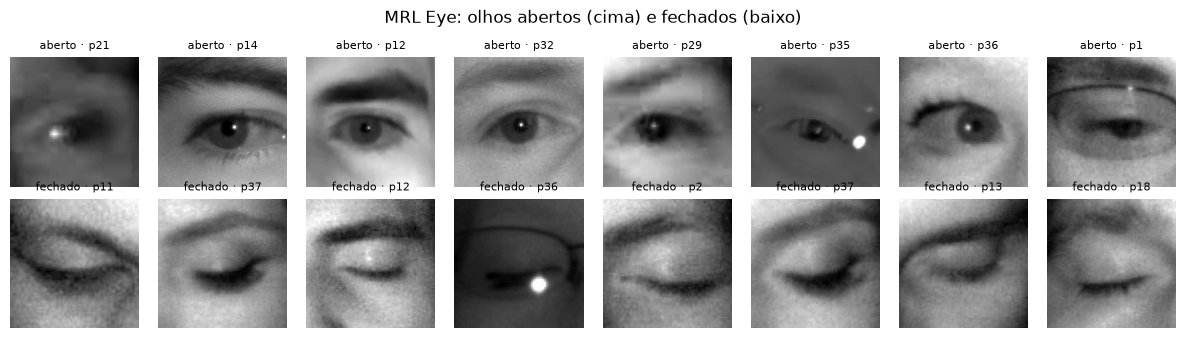

In [3]:
CAMPOS = ["pessoa", "imagem", "genero", "oculos", "aberto", "reflexo", "luz", "sensor"]

linhas = []
for arq in sorted(PASTA_MRL.glob("s*/*.png")):
    partes = arq.stem.split("_")
    linhas.append([arq] + [int(partes[0][1:])] + [int(x) for x in partes[1:]])
mrl = pd.DataFrame(linhas, columns=["arquivo"] + CAMPOS)
mrl["fechado"] = 1 - mrl["aberto"]

print(f"{len(mrl):,} imagens de {mrl.pessoa.nunique()} pessoas")
print(f"olho fechado: {mrl.fechado.mean():.1%} | com óculos: {mrl.oculos.mean():.1%} | "
      f"reflexo grande: {(mrl.reflexo == 2).mean():.1%} | luz ruim: {(mrl.luz == 0).mean():.1%}")

por_pessoa = mrl.groupby("pessoa").agg(imagens=("fechado", "size"), fechado=("fechado", "mean"))
print(f"imagens por pessoa: de {por_pessoa.imagens.min()} a {por_pessoa.imagens.max()} "
      f"(mediana {por_pessoa.imagens.median():.0f})")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([mrl[mrl.fechado == c].sample(8, random_state=SEMENTE) for c in (0, 1)])
for ax, (_, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(Image.open(r.arquivo), cmap="gray")
    ax.set_title(("fechado" if r.fechado else "aberto") + f" · p{r.pessoa}", fontsize=8)
    ax.axis("off")
plt.suptitle("MRL Eye: olhos abertos (cima) e fechados (baixo)")
plt.tight_layout(); plt.show()

### 1.3 FL3D

O FL3D é feito de 44 vídeos do NITYMED, gravados em carros reais à noite, com o rosto já recortado e um rótulo em cada frame: `alert`, `microsleep` ou `yawning`. Duas observações sobre o FL3D mudam a avaliação:

- **As piscadas foram removidas.** Os frames de piscada não estão na base, então os falsos alarmes medidos aqui são otimistas.
- **Separação por pessoa:** os autores dizem que os 5 vídeos de validação/teste têm motoristas novos. Usamos esses 5 como **teste** e os outros 39 como **calibração** (onde os limiares são escolhidos). Nada do FL3D é usado para treinar a CNN.

In [4]:
def numero_frame(nome):
    return int(re.findall(r"\d+", nome)[0])

linhas = []
for pasta in sorted(p for p in PASTA_FL3D.iterdir() if p.is_dir()):
    anot = json.load(open(pasta / "annotations_final.json"))
    for nome, info in anot.items():
        if info["driver_state"] is not None:          # 2 frames sem rótulo
            linhas.append((pasta.name, numero_frame(nome), nome, info["driver_state"]))
fl3d = pd.DataFrame(linhas, columns=["video", "frame", "nome", "estado"]).sort_values(["video", "frame"])
fl3d = fl3d.reset_index(drop=True)

videos_teste = sorted({k.split("/")[2] for k in json.load(open(PASTA_FL3D / "annotations_holdout.json"))})
fl3d["grupo"] = np.where(fl3d.video.isin(videos_teste), "teste", "calibração")

resumo = fl3d.groupby(["grupo", "video"]).estado.value_counts().unstack(fill_value=0)
resumo["segundos"] = (fl3d.groupby(["grupo", "video"]).frame.agg(lambda f: f.max() - f.min() + 1) / FPS).round(0)
print(f"{len(fl3d):,} frames em {fl3d.video.nunique()} vídeos")
print(fl3d.groupby("grupo").estado.value_counts().unstack())
print("\nvídeos de teste:")
print(resumo.loc["teste"])
# o notebook não mostra os rostos do FL3D: o repositório não guarda imagens de pessoas

53,329 frames em 44 vídeos
estado      alert  microsleep  yawning
grupo                                 
calibração  35482        8074     4769
teste        3484         795      725

vídeos de teste:
estado        alert  microsleep  yawning  segundos
video                                             
P1042762_720   2052         632       42     124.0
P1042780_720    289           0      204      40.0
P1043081_720    293           0      298      24.0
P1043086_720    327           0      181      25.0
P1043106_720    523         163        0     105.0


## 2. Linha de base: MediaPipe + EAR + regras

Antes de treinar qualquer rede, a linha de base mede o olho com geometria. O MediaPipe devolve 478 pontos do rosto, e com 6 pontos de cada olho dá para calcular o **EAR (Eye Aspect Ratio)**:

$$\text{EAR} = \frac{\lVert p_2 - p_6 \rVert + \lVert p_3 - p_5 \rVert}{2\,\lVert p_1 - p_4 \rVert}$$

O EAR é a abertura vertical dividida pela largura do olho. Ele fica perto de 0,25–0,30 com o olho aberto e cai perto de zero quando o olho fecha.

Na mesma passada pelo vídeo, guardamos o recorte de cada olho (64×64, em cinza), que a CNN vai usar na seção 4. O cálculo leva uns 30 minutos na CPU e fica em cache.

In [5]:
# pontos do MediaPipe Face Mesh: p1..p6 do EAR e o contorno de cada olho
EAR_E = [33, 160, 158, 133, 153, 144]
EAR_D = [362, 385, 387, 263, 373, 380]
CONTORNO_E = [33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246]
CONTORNO_D = [362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398]


def criar_detector():
    # o MediaPipe não abre caminhos com acento no Windows, então o modelo vai por memória
    opcoes = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_buffer=ARQ_MEDIAPIPE.read_bytes()),
        running_mode=vision.RunningMode.IMAGE, num_faces=1)
    return vision.FaceLandmarker.create_from_options(opcoes)


def pontos_do_rosto(detector, rgb):
    # devolve os 478 pontos em pixels, ou None se não achar rosto
    r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
    if not r.face_landmarks:
        return None
    h, w = rgb.shape[:2]
    return np.array([[q.x * w, q.y * h] for q in r.face_landmarks[0]])


def ear(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[i] for i in idx)
    return (np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / (2 * np.linalg.norm(p1 - p4))


def recortar_olho(cinza, contorno, fator=1.4):
    # quadrado centrado no olho, com lado = 1,4 x a largura do olho (parecido com o MRL)
    cx, cy = contorno.mean(axis=0)
    lado = fator * (contorno[:, 0].max() - contorno[:, 0].min())
    caixa = (int(cx - lado / 2), int(cy - lado / 2), int(cx + lado / 2), int(cy + lado / 2))
    return np.asarray(Image.fromarray(cinza).crop(caixa).resize((TAM, TAM), Image.BILINEAR))


def extrair_fl3d():
    arq_csv, arq_olhos = CACHE / "fl3d_ear.csv", CACHE / "fl3d_olhos.npy"
    if arq_csv.exists() and arq_olhos.exists():
        return pd.read_csv(arq_csv), np.load(arq_olhos)
    detector = criar_detector()
    ears, olhos = [], np.zeros((len(fl3d), 2, TAM, TAM), np.uint8)
    inicio = time.time()
    for i, r in enumerate(fl3d.itertuples()):
        rgb = np.asarray(Image.open(PASTA_FL3D / r.video / r.nome).convert("RGB"))
        p = pontos_do_rosto(detector, rgb)
        if p is None:
            ears.append((np.nan, np.nan, False))
            continue
        cinza = np.asarray(Image.fromarray(rgb).convert("L"))
        olhos[i, 0] = recortar_olho(cinza, p[CONTORNO_E])
        olhos[i, 1] = recortar_olho(cinza, p[CONTORNO_D])
        ears.append((ear(p, EAR_E), ear(p, EAR_D), True))
    print(f"{(time.time() - inicio) / len(fl3d) * 1000:.1f} ms por frame")
    tab = pd.DataFrame(ears, columns=["ear_e", "ear_d", "rosto"])
    tab.to_csv(arq_csv, index=False)
    np.save(arq_olhos, olhos)
    return tab, olhos


tab_ear, olhos_fl3d = extrair_fl3d()
fl3d[["ear_e", "ear_d", "rosto"]] = tab_ear[["ear_e", "ear_d", "rosto"]].values
fl3d["ear"] = fl3d[["ear_e", "ear_d"]].astype(float).mean(axis=1)
fl3d["rosto"] = fl3d["rosto"].astype(bool)
print(f"rosto encontrado em {fl3d.rosto.mean():.2%} dos frames")
print(fl3d.groupby("estado").ear.describe()[["count", "mean", "50%", "std"]].round(3))

rosto encontrado em 98.51% dos frames
              count   mean    50%    std
estado                                  
alert       38368.0  0.303  0.301  0.070
microsleep   8684.0  0.091  0.082  0.047
yawning      5481.0  0.189  0.191  0.073


### 2.1 Calibração por pessoa

O EAR de olho aberto muda de pessoa para pessoa, então um limiar fixo como 0,2 falha. Cada vídeo é calibrado pelo próprio começo: o **EAR de referência é o percentil 75 dos primeiros 30 s**, e o sinal usado é `1 − EAR / referência` (0 = olho como na calibração, 1 = olho fechado). Usamos o percentil 75, e não a mediana, porque alguns vídeos já começam com microssono.

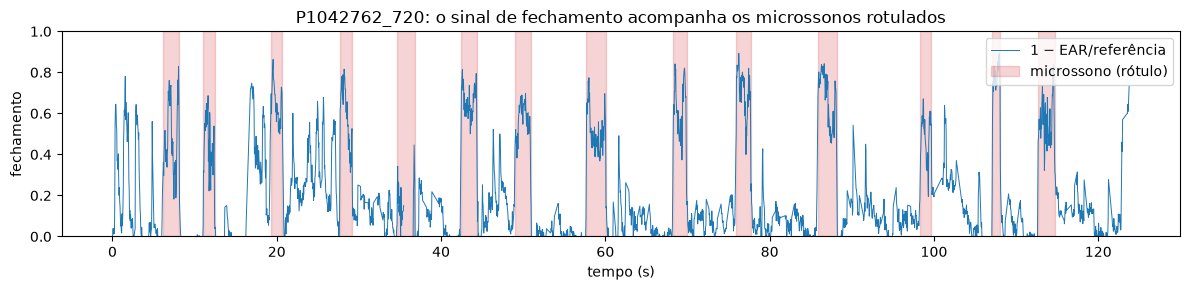

In [6]:
def referencia(d, segundos=30):
    inicio = d.frame.min()
    return d.loc[d.frame < inicio + segundos * FPS, "ear"].quantile(0.75)

ref = fl3d.groupby("video").apply(referencia, include_groups=False)
fl3d["fech_ear"] = (1 - fl3d.ear / fl3d.video.map(ref)).clip(0, 1)

v = "P1042762_720"   # vídeo de teste com microssonos
d = fl3d[fl3d.video == v]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(d.frame / FPS, d.fech_ear, lw=0.7, color="tab:blue", label="1 − EAR/referência")
ms = d.estado.eq("microsleep").values
ax.fill_between(d.frame / FPS, 0, 1, where=ms, color="tab:red", alpha=0.2, step="mid", label="microssono (rótulo)")
ax.set_xlabel("tempo (s)"); ax.set_ylabel("fechamento"); ax.set_ylim(0, 1); ax.legend(loc="upper right")
ax.set_title(f"{v}: o sinal de fechamento acompanha os microssonos rotulados")
plt.tight_layout(); plt.show()

### 2.2 Olho fechado por frame

Primeiro, a pergunta mais simples: o sinal separa os frames de microssono dos outros? O limiar é escolhido nos vídeos de calibração (maior F1) e aplicado nos de teste. Como `microsleep` é a classe rara (cerca de 17% dos frames), a métrica principal é a **AUC-PR**.

In [7]:
def limiar_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.maximum(p + r, 1e-9)
    return t[np.argmax(f1[:-1])]


def metricas_frame(d, col, limiar):
    y, s = d.estado.eq("microsleep").values, d[col].values
    p, r, f1, _ = precision_recall_fscore_support(y, s >= limiar, average="binary", zero_division=0)
    return {"AUC-PR": average_precision_score(y, s), "precisão": p, "recall": r, "F1": f1}


calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_EAR = limiar_f1(calib.estado.eq("microsleep"), calib.fech_ear)
print(f"limiar escolhido na calibração: fechamento >= {LIMIAR_EAR:.3f} "
      f"(EAR abaixo de {1 - LIMIAR_EAR:.0%} da referência)")
pd.DataFrame({"calibração": metricas_frame(calib, "fech_ear", LIMIAR_EAR),
              "teste": metricas_frame(teste, "fech_ear", LIMIAR_EAR)}).T.round(3)

limiar escolhido na calibração: fechamento >= 0.525 (EAR abaixo de 47% da referência)


,AUC-PR,precisão,recall,F1
calibração,0.834,0.774,0.789,0.782
teste,0.658,0.637,0.694,0.664


### 2.3 Do frame ao alerta: regras do Euro NCAP

Um frame com o olho fechado pode ser só uma piscada. O alerta só dispara quando o olho fica fechado **por tempo seguido**. Os limiares vêm do protocolo do Euro NCAP (pesquisa, seção Indústria):

| Nível | Olho fechado por | Alerta |
|---|---|---|
| Microssono | 1 a 2 s | som forte |
| Sono | 3 s ou mais | som urgente + "pare em local seguro" |
| Sem resposta | 6 s ou mais | máximo |

Antes de fixar o tempo mínimo, vale olhar quanto duram os microssonos do FL3D. Um **episódio** é um trecho seguido de frames `microsleep`, juntando buracos de até 0,5 s (frames removidos da base).

254 episódios de microssono | duração mediana 1.4 s | 35% com menos de 1 s | 5% com 3 s ou mais


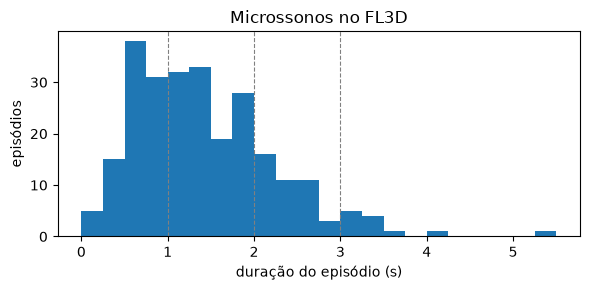

In [8]:
def trechos(mascara):
    # trechos seguidos de True -> lista de (início, fim), fim incluso
    m = np.r_[False, mascara, False].astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))


def unir(lista, buraco):
    # junta trechos separados por até `buraco` frames
    saida = []
    for a, b in lista:
        if saida and a - saida[-1][1] - 1 <= buraco:
            saida[-1] = (saida[-1][0], b)
        else:
            saida.append((a, b))
    return saida


def linha_do_tempo(d):
    # um valor por frame do vídeo, incluindo os frames que a base removeu (NaN)
    tl = pd.DataFrame({"frame": np.arange(d.frame.min(), d.frame.max() + 1)})
    return tl.merge(d, on="frame", how="left")


BURACO_EP = int(0.5 * FPS)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
episodios = {v: unir(trechos(tl.estado.eq("microsleep").values), BURACO_EP) for v, tl in tempo.items()}

dur = np.array([(b - a + 1) / FPS for eps in episodios.values() for a, b in eps])
print(f"{len(dur)} episódios de microssono | duração mediana {np.median(dur):.1f} s | "
      f"{(dur < 1).mean():.0%} com menos de 1 s | {(dur >= 3).mean():.0%} com 3 s ou mais")
plt.figure(figsize=(6, 3))
plt.hist(dur, bins=np.arange(0, dur.max() + 0.25, 0.25))
for x in (1, 2, 3):
    plt.axvline(x, color="gray", ls="--", lw=0.8)
plt.xlabel("duração do episódio (s)"); plt.ylabel("episódios"); plt.title("Microssonos no FL3D")
plt.tight_layout(); plt.show()

A regra de alerta:

1. o frame conta como **fechado** quando o sinal passa do limiar da seção 2.2;
2. trechos fechados separados por até 3 frames (0,12 s) viram um só, para um frame ruim não zerar a contagem;
3. o **alerta dispara** quando um trecho fechado chega a **T segundos**, uma vez por trecho.

Um alerta é **acerto** se cai dentro de um episódio (com tolerância de 0,5 s depois do fim) e **falso alarme** se não. As métricas são as da pesquisa: recall de evento, falsos alarmes por hora de direção alerta e atraso. O T é escolhido na calibração, testando de 0,4 s a 2 s.

In [9]:
BURACO_FECH = 3
TOL = int(0.5 * FPS)


def alertas(tl, col, limiar, T):
    fechado = (tl[col] >= limiar).fillna(False).values
    n = int(round(T * FPS))
    return [a + n - 1 for a, b in unir(trechos(fechado), BURACO_FECH) if b - a + 1 >= n]


def avaliar_eventos(videos, col, limiar, T):
    n_ep = acertos = falsos = 0
    atrasos, horas_alerta = [], 0.0
    for v in videos:
        tl, eps = tempo[v], episodios[v]
        detectado = set()
        for al in alertas(tl, col, limiar, T):
            dentro = [i for i, (a, b) in enumerate(eps) if a - TOL <= al <= b + TOL]
            if not dentro:
                falsos += 1
            for i in dentro:
                if i not in detectado:
                    detectado.add(i)
                    atrasos.append(max(al - eps[i][0], 0) / FPS)
        n_ep += len(eps)
        acertos += len(detectado)
        horas_alerta += tl.estado.eq("alert").sum() / FPS / 3600
    return {"T (s)": T, "episódios": n_ep, "recall de evento": acertos / max(n_ep, 1),
            "falsos alarmes": falsos, "falsos/hora": falsos / horas_alerta,
            "atraso mediano (s)": np.median(atrasos) if atrasos else np.nan,
            "horas alerta": horas_alerta}


def escolher_T(col, limiar, Ts=(0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0)):
    vids = sorted(fl3d.loc[fl3d.grupo == "calibração", "video"].unique())
    tab = pd.DataFrame([avaliar_eventos(vids, col, limiar, T) for T in Ts])
    # F1 de evento: recall de evento x fração dos alertas que acertam
    tab["F1 evento"] = [
        2 * r * p / (r + p) if r + p else 0
        for r, p in zip(tab["recall de evento"],
                        tab["recall de evento"] * tab["episódios"]
                        / np.maximum(tab["recall de evento"] * tab["episódios"] + tab["falsos alarmes"], 1))]
    return tab, tab.loc[tab["F1 evento"].idxmax(), "T (s)"]


tab_T_ear, T_EAR = escolher_T("fech_ear", LIMIAR_EAR)
print(f"T escolhido na calibração: {T_EAR} s")
tab_T_ear.round(3)

T escolhido na calibração: 0.4 s


,T (s),episódios,recall de evento,falsos alarmes,falsos/hora,atraso mediano (s),horas alerta,F1 evento
0,0.4,228,0.759,56,142.044,0.36,0.394,0.757
1,0.6,228,0.680,37,93.850,0.56,0.394,0.738
2,0.8,228,0.570,27,68.485,0.76,0.394,0.675
3,1.0,228,0.500,22,55.803,0.96,0.394,0.626
4,1.2,228,0.421,17,43.120,1.16,0.394,0.563
5,1.5,228,0.307,11,27.901,1.48,0.394,0.453
6,2.0,228,0.154,5,12.682,1.96,0.394,0.261


In [10]:
res_ear = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_EAR)
res_ear_1s = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, 1.0)
pd.DataFrame({f"EAR, T = {T_EAR} s": res_ear, "EAR, T = 1 s (Euro NCAP)": res_ear_1s}).T.round(3)

,T (s),episódios,recall de evento,falsos alarmes,falsos/hora,atraso mediano (s),horas alerta
"EAR, T = 0.4 s",0.4,26.0,0.846,6.0,154.994,0.36,0.039
"EAR, T = 1 s (Euro NCAP)",1.0,26.0,0.269,3.0,77.497,1.00,0.039


### Observações da linha de base

- **O MediaPipe funciona bem nesses vídeos:** acha o rosto em 98,5% dos frames, a cerca de 28 ms por frame na CPU (tempo medido na primeira execução, antes do cache).
- **O EAR separa bem os estados:** a mediana é 0,30 em alerta, 0,08 em microssono e 0,19 em bocejo. O bocejo aperta o olho, e por isso é a principal fonte de confusão.
- **Por frame, o teste cai em relação à calibração** (AUC-PR de 0,83 para 0,66). Os motoristas do teste são novos, e o limiar escolhido em outras pessoas não serve tão bem neles.
- **T = 0,4 s ganhou na calibração, mas não deve ir para a demo.** O FL3D tirou as piscadas, então não há fechamento curto em alerta para gerar falso alarme, e 35% dos microssonos duram menos de 1 s. Com uma webcam real, uma piscada longa (0,3 a 0,4 s) dispararia o alerta. Na demo usamos T = 1 s, como no Euro NCAP, que no teste acha 27% dos episódios (contra 85% com 0,4 s).
- **Os falsos alarmes por hora não são confiáveis aqui:** o teste tem só 2,3 minutos de direção em alerta, então 6 alarmes viram 155 por hora.

### 2.4 Os três níveis do alerta

A mesma lógica dá os três níveis do Euro NCAP. Cada trecho fechado recebe o nível mais alto que alcança. No FL3D quase não há trechos de 3 s ou mais, então os níveis "sono" e "sem resposta" ficam implementados mas pouco testados aqui. Eles serão testados na demo com a webcam, com sono encenado.

In [11]:
NIVEIS = [(6.0, "sem resposta"), (3.0, "sono"), (1.0, "microssono")]


def nivel(duracao_s):
    for minimo, nome in NIVEIS:
        if duracao_s >= minimo:
            return nome
    return None


contagem = {}
for v in fl3d.video.unique():
    fechado = (tempo[v]["fech_ear"] >= LIMIAR_EAR).fillna(False).values
    for a, b in unir(trechos(fechado), BURACO_FECH):
        n = nivel((b - a + 1) / FPS)
        if n:
            contagem[n] = contagem.get(n, 0) + 1
print("trechos fechados por nível, nos 44 vídeos:", contagem)

trechos fechados por nível, nos 44 vídeos: {'microssono': 140, 'sono': 8}


## 3. CNN de olho: MobileNetV3 com fine-tuning

O EAR depende de 6 pontos e erra quando o MediaPipe erra a pálpebra (óculos, reflexo, cabeça de lado). A CNN olha o recorte inteiro do olho e devolve P(olho fechado).

- **Modelo:** MobileNetV3-Small pré-treinada no ImageNet, com a última camada trocada por 1 saída. É pequena (cerca de 1,5 M de parâmetros) e roda em tempo real na CPU.
- **Dados:** MRL Eye, em cinza, 64×64, repetido nos 3 canais.
- **Separação por pessoa:** as 37 pessoas são divididas em treino, validação e teste **antes** de qualquer coisa, então nenhum rosto do teste aparece no treino.

In [12]:
def carregar_mrl():
    arq = CACHE / f"mrl_{TAM}.npy"
    if arq.exists():
        return np.load(arq)
    x = np.stack([np.asarray(Image.open(a).convert("L").resize((TAM, TAM), Image.BILINEAR))
                  for a in mrl.arquivo])
    np.save(arq, x)
    return x


x_mrl = carregar_mrl()
y_mrl = mrl.fechado.values.astype(np.float32)

# 1º corte: teste (~20% das pessoas); 2º corte: validação (~15% do resto)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_resto, idx_te = next(gss.split(x_mrl, y_mrl, groups=mrl.pessoa))
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEMENTE)
i_tr, i_va = next(gss.split(idx_resto, groups=mrl.pessoa.values[idx_resto]))
idx_tr, idx_va = idx_resto[i_tr], idx_resto[i_va]

pessoas = {n: set(mrl.pessoa.values[i]) for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]}
assert not (pessoas["treino"] & pessoas["validação"]) and not (pessoas["treino"] & pessoas["teste"]) \
    and not (pessoas["validação"] & pessoas["teste"]), "uma pessoa caiu em duas partições"
for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]:
    print(f"{n:10s}: {len(i):6,} imagens, {len(pessoas[n]):2d} pessoas, {y_mrl[i].mean():.1%} fechados, "
          f"{mrl.oculos.values[i].mean():.0%} com óculos")
print("pessoas no teste:", sorted(int(p) for p in pessoas["teste"]))

treino    : 54,197 imagens, 24 pessoas, 49.2% fechados, 30% com óculos
validação :  6,559 imagens,  5 pessoas, 54.2% fechados, 19% com óculos
teste     : 24,142 imagens,  8 pessoas, 48.5% fechados, 27% com óculos
pessoas no teste: [5, 7, 14, 18, 26, 27, 30, 36]


### 3.1 Treino

O aumento de dados roda na GPU, por lote: espelhamento horizontal, brilho, contraste, gama, pequeno deslocamento e ruído. A ideia é aproximar o infravermelho do MRL da webcam RGB noturna do FL3D. O treino usa AdamW com taxa cosseno e guarda o modelo da época com menor perda na validação. O modelo fica em cache em `data/modelos/`.

In [13]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def preparar(x_uint8):
    # uint8 [B, H, W] -> float normalizado [B, 3, H, W]
    x = x_uint8.to(DEVICE, non_blocking=True).float().div(255).unsqueeze(1)
    return x


def normalizar(x):
    return (x.repeat(1, 3, 1, 1) - MEDIA) / DESVIO


def aumentar(x):
    B = x.shape[0]
    def u(a, b):
        return torch.empty(B, 1, 1, 1, device=x.device).uniform_(a, b)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(-1), x)
    x = x.clamp(1e-4, 1) ** u(0.7, 1.4)                                   # gama
    m = x.mean(dim=(2, 3), keepdim=True)
    x = (x - m) * u(0.7, 1.3) + m + u(-0.15, 0.15)                        # contraste e brilho
    dx, dy = np.random.randint(-4, 5, size=2)
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))             # deslocamento
    x = x + torch.randn_like(x) * u(0, 0.04)                               # ruído
    return x.clamp(0, 1)


def criar_modelo():
    m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)
    return m.to(DEVICE)


@torch.no_grad()
def prever(modelo, x_uint8, lote=1024):
    modelo.eval()
    saidas = []
    for i in range(0, len(x_uint8), lote):
        xb = normalizar(preparar(torch.from_numpy(x_uint8[i:i + lote])))
        saidas.append(torch.sigmoid(modelo(xb)).squeeze(1).cpu())
    return torch.cat(saidas).numpy()


def treinar(nome, i_tr, i_va, epocas=10, lote=256, lr=1e-3):
    arq = PASTA_MODELOS / f"{nome}.pt"
    modelo = criar_modelo()
    if arq.exists():
        salvo = torch.load(arq, map_location=DEVICE)
        modelo.load_state_dict(salvo["pesos"])
        print(f"{nome}: carregado do cache (melhor época {salvo['melhor']})")
        return modelo, salvo["historico"]

    torch.manual_seed(SEMENTE); np.random.seed(SEMENTE)
    # o MRL em 64x64 cabe inteiro na GPU (~250 MB), o que evita copiar lote a lote
    x_tr, y_tr = torch.from_numpy(x_mrl[i_tr]).to(DEVICE), torch.from_numpy(y_mrl[i_tr]).to(DEVICE)
    x_va, y_va = torch.from_numpy(x_mrl[i_va]).to(DEVICE), torch.from_numpy(y_mrl[i_va]).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    passos = epocas * int(np.ceil(len(x_tr) / lote))
    agenda = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=passos, pct_start=0.15)
    perda_fn = nn.BCEWithLogitsLoss()
    hist = {k: [] for k in ("perda_tr", "acc_tr", "perda_va", "acc_va")}
    melhor, melhor_perda, melhor_pesos = 0, np.inf, None

    for ep in range(1, epocas + 1):
        modelo.train()
        ordem = torch.randperm(len(x_tr), device=DEVICE)
        soma = acertos = 0
        t0 = time.time()
        for i in range(0, len(ordem), lote):
            j = ordem[i:i + lote]
            xb = normalizar(aumentar(preparar(x_tr[j])))
            yb = y_tr[j]
            logit = modelo(xb).squeeze(1)
            perda = perda_fn(logit, yb)
            opt.zero_grad(); perda.backward(); opt.step(); agenda.step()
            soma += perda.item() * len(j)
            acertos += ((logit > 0).float() == yb).sum().item()
        modelo.eval()
        with torch.no_grad():
            logit_va = torch.cat([modelo(normalizar(preparar(x_va[i:i + 1024]))).squeeze(1)
                                  for i in range(0, len(x_va), 1024)])
            perda_va = perda_fn(logit_va, y_va).item()
            acc_va = ((logit_va > 0).float() == y_va).float().mean().item()
        hist["perda_tr"].append(soma / len(x_tr)); hist["acc_tr"].append(acertos / len(x_tr))
        hist["perda_va"].append(perda_va); hist["acc_va"].append(acc_va)
        if perda_va < melhor_perda:
            melhor, melhor_perda = ep, perda_va
            melhor_pesos = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        print(f"época {ep:2d}: perda {hist['perda_tr'][-1]:.4f} / val {perda_va:.4f} | "
              f"acc {hist['acc_tr'][-1]:.4f} / val {acc_va:.4f} | {time.time() - t0:.0f} s")

    modelo.load_state_dict(melhor_pesos)
    torch.save({"pesos": melhor_pesos, "historico": hist, "melhor": melhor}, arq)
    print(f"melhor época: {melhor}")
    return modelo, hist


cnn, hist = treinar("cnn_olho_por_pessoa", idx_tr, idx_va)

cnn_olho_por_pessoa: carregado do cache (melhor época 8)


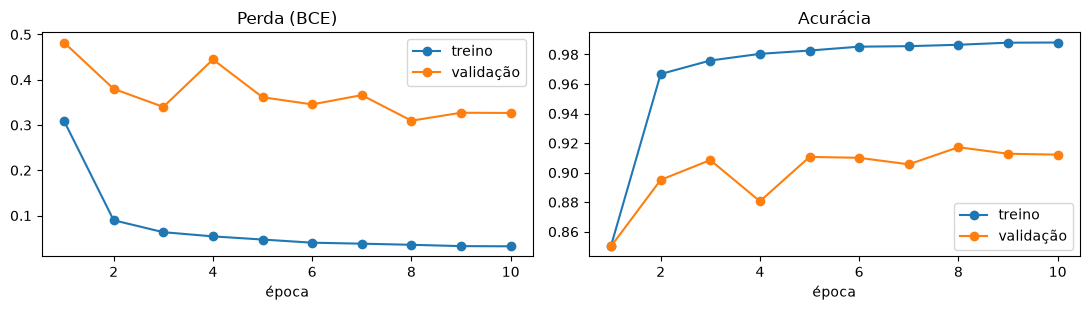

diferença treino − validação na última época: +0.0759 de acurácia


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ep = np.arange(1, len(hist["perda_tr"]) + 1)
axes[0].plot(ep, hist["perda_tr"], "o-", label="treino"); axes[0].plot(ep, hist["perda_va"], "o-", label="validação")
axes[0].set_title("Perda (BCE)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(ep, hist["acc_tr"], "o-", label="treino"); axes[1].plot(ep, hist["acc_va"], "o-", label="validação")
axes[1].set_title("Acurácia"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"diferença treino − validação na última época: "
      f"{hist['acc_tr'][-1] - hist['acc_va'][-1]:+.4f} de acurácia")

### 3.2 Teste em pessoas novas

O limiar de P(fechado) é escolhido na validação (maior F1) e aplicado no teste. Além do total, o resultado sai **por pessoa** e por condição (óculos, reflexo, luz), porque a média esconde quem o modelo erra.

limiar (validação): 0.769
teste: acurácia 0.9664 | precisão 0.9691 | recall 0.9613 | F1 0.9652 | AUC-PR 0.9918


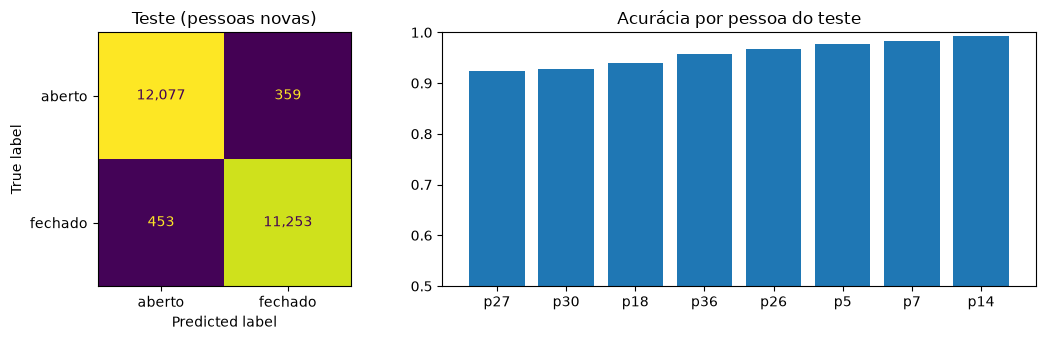

por pessoa: média 0.9582, desvio 0.0262, pior 0.9233


acurácia  imagens
óculos  com        0.9235     6614
        sem        0.9825    17528
reflexo grande     0.8878     3244
        nenhum     0.9789    19312
        pequeno    0.9748     1586
luz     boa        0.9775     8627
        ruim       0.9602    15515

In [15]:
p_va, p_te = prever(cnn, x_mrl[idx_va]), prever(cnn, x_mrl[idx_te])
LIMIAR_CNN_MRL = limiar_f1(y_mrl[idx_va], p_va)
y_te = y_mrl[idx_te]
prev_te = (p_te >= LIMIAR_CNN_MRL).astype(int)
pr, rc, f1, _ = precision_recall_fscore_support(y_te, prev_te, average="binary")
print(f"limiar (validação): {LIMIAR_CNN_MRL:.3f}")
print(f"teste: acurácia {(prev_te == y_te).mean():.4f} | precisão {pr:.4f} | recall {rc:.4f} | "
      f"F1 {f1:.4f} | AUC-PR {average_precision_score(y_te, p_te):.4f}")

te = mrl.iloc[idx_te].assign(acerto=(prev_te == y_te))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1.6]})
ConfusionMatrixDisplay(confusion_matrix(y_te, prev_te), display_labels=["aberto", "fechado"]).plot(
    ax=axes[0], colorbar=False, values_format=",")
axes[0].set_title("Teste (pessoas novas)")
acc_p = te.groupby("pessoa").acerto.mean().sort_values()
axes[1].bar([f"p{p}" for p in acc_p.index], acc_p.values)
axes[1].set_ylim(min(0.5, acc_p.min() - 0.05), 1); axes[1].set_title("Acurácia por pessoa do teste")
plt.tight_layout(); plt.show()
print(f"por pessoa: média {acc_p.mean():.4f}, desvio {acc_p.std():.4f}, pior {acc_p.min():.4f}")

cond = pd.concat({
    "óculos": te.groupby(te.oculos.map({0: "sem", 1: "com"})).acerto.agg(["mean", "size"]),
    "reflexo": te.groupby(te.reflexo.map({0: "nenhum", 1: "pequeno", 2: "grande"})).acerto.agg(["mean", "size"]),
    "luz": te.groupby(te.luz.map({0: "ruim", 1: "boa"})).acerto.agg(["mean", "size"]),
}).rename(columns={"mean": "acurácia", "size": "imagens"})
cond.round(4)

### Observações da CNN

- **Em 8 pessoas novas:** 96,6% de acurácia, F1 de 0,965 e AUC-PR de 0,992. A pior pessoa fica em 92,3%.
- **Os pontos fracos são óculos (92,4%) e reflexo grande (88,8%),** contra 98% sem eles. É o mesmo problema que a pesquisa aponta para câmeras no carro.
- **Overfitting:** o treino chega a 98,8% e a validação para em cerca de 91%. A distância é entre pessoas: a validação tem só 5, e o teste, com outras 8, fica em 96,6%. O modelo guardado é o da época com menor perda na validação (época 8), então ele não segue as últimas épocas de treino.

### 3.3 Quanto o vazamento inflaria o resultado

A pesquisa avisa que dividir imagens ao acaso põe o mesmo rosto no treino e no teste. Para medir isso, a mesma receita é treinada com divisão aleatória (mesmos tamanhos) e as duas notas de teste são comparadas.

In [16]:
ss = ShuffleSplit(n_splits=1, test_size=len(idx_te) / len(x_mrl), random_state=SEMENTE)
idx_resto_a, idx_te_a = next(ss.split(x_mrl))
ss = ShuffleSplit(n_splits=1, test_size=len(idx_va) / len(idx_resto_a), random_state=SEMENTE)
i_tr_a, i_va_a = next(ss.split(idx_resto_a))
cnn_aleat, _ = treinar("cnn_olho_aleatoria", idx_resto_a[i_tr_a], idx_resto_a[i_va_a])

lim_a = limiar_f1(y_mrl[idx_resto_a[i_va_a]], prever(cnn_aleat, x_mrl[idx_resto_a[i_va_a]]))
acc_aleat = ((prever(cnn_aleat, x_mrl[idx_te_a]) >= lim_a) == y_mrl[idx_te_a]).mean()
acc_pessoa = (prev_te == y_te).mean()
print(f"divisão aleatória: {acc_aleat:.4f} | divisão por pessoa: {acc_pessoa:.4f} | "
      f"diferença: {acc_aleat - acc_pessoa:+.4f}")

cnn_olho_aleatoria: carregado do cache (melhor época 8)


divisão aleatória: 0.9887 | divisão por pessoa: 0.9664 | diferença: +0.0223


Com divisão aleatória a nota seria 98,9%, ou 2,2 pontos acima da divisão por pessoa. A diferença é pequena porque o estado do olho é uma tarefa fácil. Em sonolência, onde o modelo pode decorar o jeito de cada pessoa, a pesquisa mostra quedas muito maiores. A divisão por pessoa continua sendo a regra em todo o projeto.

## 4. CNN no vídeo: trocando o EAR pela CNN

Agora a CNN treinada no MRL (infravermelho, só o olho) recebe os recortes de olho do FL3D (webcam RGB à noite, em carro real), que ela nunca viu. O sinal de fechamento passa a ser a média de P(fechado) dos dois olhos, e o resto do sistema é igual: limiar e T escolhidos na calibração, resultado no teste.

CNN: limiar 0.503, T = 0.4 s (escolhidos na calibração)


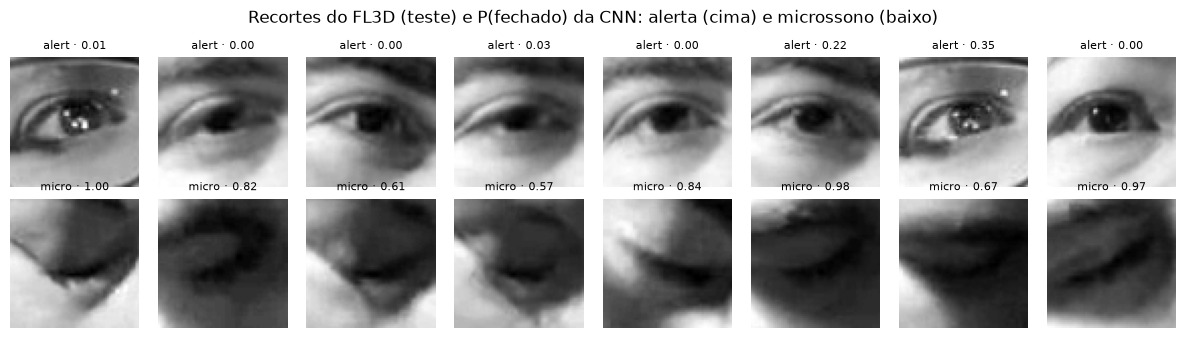

In [17]:
p_olhos = prever(cnn, olhos_fl3d.reshape(-1, TAM, TAM)).reshape(-1, 2)
fl3d["fech_cnn"] = np.where(fl3d.rosto, p_olhos.mean(axis=1), np.nan)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}

calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_CNN = limiar_f1(calib.estado.eq("microsleep"), calib.fech_cnn)
tab_T_cnn, T_CNN = escolher_T("fech_cnn", LIMIAR_CNN)
print(f"CNN: limiar {LIMIAR_CNN:.3f}, T = {T_CNN} s (escolhidos na calibração)")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([teste[teste.estado == e].sample(8, random_state=SEMENTE) for e in ("alert", "microsleep")])
for ax, (i, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(olhos_fl3d[i, 0], cmap="gray")
    ax.set_title(f"{r.estado[:5]} · {r.fech_cnn:.2f}", fontsize=8); ax.axis("off")
plt.suptitle("Recortes do FL3D (teste) e P(fechado) da CNN: alerta (cima) e microssono (baixo)")
plt.tight_layout(); plt.show()

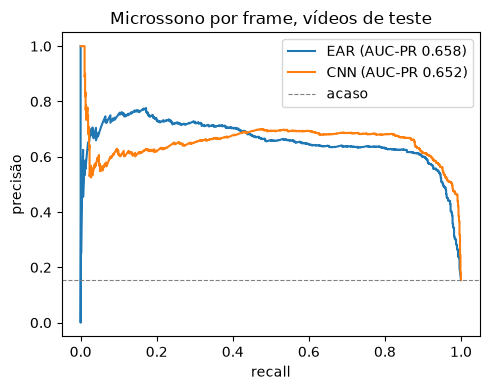

,AUC-PR,precisão,recall,F1
EAR (frame),0.658,0.637,0.694,0.664
CNN (frame),0.652,0.659,0.877,0.752


,T (s),episódios,recall de evento,falsos alarmes,falsos/hora,atraso mediano (s),horas alerta
EAR (evento),0.4,26.0,0.846,6.0,154.994,0.36,0.039
CNN (evento),0.4,26.0,0.846,11.0,284.156,0.40,0.039


In [18]:
quadro = pd.DataFrame({
    "EAR (frame)": metricas_frame(teste, "fech_ear", LIMIAR_EAR),
    "CNN (frame)": metricas_frame(teste, "fech_cnn", LIMIAR_CNN),
}).T
eventos = pd.DataFrame({
    "EAR (evento)": avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_EAR),
    "CNN (evento)": avaliar_eventos(videos_teste, "fech_cnn", LIMIAR_CNN, T_CNN),
}).T

fig, ax = plt.subplots(figsize=(5, 4))
for col, nome in [("fech_ear", "EAR"), ("fech_cnn", "CNN")]:
    p, r, _ = precision_recall_curve(teste.estado.eq("microsleep"), teste[col])
    ax.plot(r, p, label=f"{nome} (AUC-PR {average_precision_score(teste.estado.eq('microsleep'), teste[col]):.3f})")
ax.axhline(teste.estado.eq("microsleep").mean(), color="gray", ls="--", lw=0.8, label="acaso")
ax.set_xlabel("recall"); ax.set_ylabel("precisão"); ax.set_title("Microssono por frame, vídeos de teste")
ax.legend(); plt.tight_layout(); plt.show()

display(quadro.round(3))
display(eventos.round(3))

### 4.1 Olho fechado ou microssono?

A CNN aprendeu **olho fechado**, e o rótulo do FL3D é **microssono**. Os dois não são a mesma coisa: um bocejo aperta o olho, e um olhar para baixo fecha a pálpebra. Para ver onde cada sinal erra, a tabela mostra o sinal médio por estado nos vídeos de teste.

In [19]:
teste.groupby("estado")[["fech_ear", "fech_cnn"]].agg(["mean", "median"]).round(3)

fech_ear        fech_cnn       
               mean median     mean median
estado                                    
alert         0.107  0.070    0.076  0.013
microsleep    0.598  0.611    0.766  0.835
yawning       0.342  0.289    0.308  0.054

### Observações da CNN no vídeo

- **A CNN funciona fora do domínio de treino.** Treinada em infravermelho de laboratório, ela chega a F1 de 0,75 por frame na webcam noturna, contra 0,66 do EAR, com recall bem maior (0,88 contra 0,69). A AUC-PR é a mesma (0,65 e 0,66).
- **No alerta, empata no recall e perde nos falsos alarmes:** as duas acham 22 dos 26 episódios, mas a CNN dispara 11 falsos alarmes contra 6 do EAR.
- **A CNN se confunde menos com o bocejo na maioria dos frames** (mediana 0,05, contra 0,29 do EAR), mas alguns bocejos dão P(fechado) alta.
- **O recorte piora justamente no microssono.** Quando a cabeça cai, o quadrado pega pálpebra e bochecha borradas (figura acima). Parte do acerto pode vir de "não estou vendo um olho aberto", e não de "olho fechado". Alinhar o recorte pela linha dos olhos é o próximo ajuste.

## 5. Resumo e próximos passos

| Etapa | Resultado no teste |
|---|---|
| MediaPipe no FL3D | Rosto em 98,5% dos frames, cerca de 28 ms por frame na CPU (1ª execução) |
| EAR por frame (microssono) | AUC-PR 0,66 · F1 0,66 |
| CNN no MRL (8 pessoas novas) | Acurácia 96,6% · F1 0,965 · pior pessoa 92,3% |
| CNN no FL3D por frame | AUC-PR 0,65 · F1 0,75 |
| Alerta (T = 0,4 s) | 22 de 26 episódios, com EAR e com CNN; 6 e 11 falsos alarmes |

**Conclusão:** a linha de base e a CNN já detectam a maior parte dos microssonos em vídeo real à noite, com pessoas que nenhum dos dois viu. O teste, porém, é pequeno (2 vídeos com microssono e 2,3 minutos de alerta) e não tem piscadas, então os números de falso alarme ainda não dizem como o sistema se comporta numa viagem.

**Próximos passos até 17/11:**

1. **Modelo temporal:** GRU ou TCN sobre a série de P(fechado), treinada no UTA-RLDD recortado (Kaggle) com separação por pessoa, para a sonolência na janela de 30 a 60 s.
2. **Recorte do olho:** alinhar pela linha dos olhos e medir de novo quando a cabeça cai.
3. **Domínio RGB:** juntar ao treino uma base RGB de olhos (por exemplo, CEW) e comparar com o MRL sozinho.
4. **Demo com webcam:** os três níveis do Euro NCAP com T = 1 s e estado "sem rosto visível".
5. **Falsos alarmes reais:** gravações curtas do grupo, encenadas, na mesa ou em carro **desligado e parado**, com piscadas e conversa. Essas gravações servem só para teste.